# Modeling & Persiapan Deployment - Kelompok 1
**Mata Kuliah:** Sains Data &nbsp;|&nbsp; **Kelas:** A &nbsp;|&nbsp; **Topik:** Retensi Pelanggan Ritel (Online Retail II)

## Anggota Kelompok
| No | Nama | NIM |
|---|---|---|
| 1 | Akhmad Fajri Mubarak | 2108561113 |
| 2 | Nayla Lareina Widyastuti Seregar | 2408561001 |
| 3 | I Gusti Ayu Agung Arda Swari | 2408561002 |
| 4 | Si Ngurah Putu Juliarta | 2408561004 |
| 5 | I Nyoman Gede Wresa Maharamya | 2408561007 |

## Tujuan
Melatih, mengevaluasi, dan menyimpan **3 model** dari dataset hasil Tugas Akhir IV sehingga **siap dipakai website**:

| No | Model | Pertanyaan bisnis | Input (dari TA IV) | Output untuk web |
|---|---|---|---|---|
| 1 | **Classification** (prediksi churn) | Siapa yang kemungkinan tidak belanja lagi dalam 90 hari? | `03_classification_ready.csv` | Probabilitas churn + level risiko |
| 2 | **Clustering** (segmentasi) | Pelanggan termasuk tipe apa? | `04_clustering_profil.csv` | Nama segmen + rekomendasi aksi |
| 3 | **Association Rules** | Produk apa yang sering dibeli bersama? | `05_association_basket_onehot.pkl` | Rekomendasi produk untuk keranjang |

## Perbaikan di Versi 2
| Model | Versi 1 | Versi 2 | Dibuktikan di |
|---|---|---|---|
| Churn | fitur RFM (3) | RFM + **`CustomerAge`** + **`RecencyRatio`** (5) | Bagian 2.2: perbandingan berpasangan 20 fold CV |
| Segmentasi | 5 fitur, k = 4: pelanggan baru tercampur ke segmen HILANG | 6 fitur (+ **`CustomerAge`**), k = 5: muncul segmen **BARU** | Bagian 3.2: perbandingan v1 vs v2 |
| Rekomendasi | `min_support` 1 % (± 130 produk pemicu) | `min_support` **0,5 %** (± 400 produk pemicu) | Bagian 4.2: uji temporal beberapa nilai support |

`CustomerAge` = hari sejak pembelian **pertama** = `Recency + TenureDays`. Fitur ini memakai `TenureDays`, tetapi dalam bentuk yang bisa membedakan pelanggan baru (umur kecil) dari pelanggan lama yang sudah pergi (umur besar). Kalau `TenureDays` dipakai mentah, hasilnya justru memburuk, karena nilainya 0 untuk semua pembeli sekali.

## Prinsip agar model siap deployment
1. **Preprocessing ikut disimpan di dalam model** (`sklearn.Pipeline`: `log1p` → `StandardScaler` → model). Web cukup mengirim nilai asli (`Recency`, `Frequency`, `Monetary`, ...), tanpa perlu meniru scaling.
2. **Model berversi** di folder `models/<versi>/` + penunjuk `models/current.json`, sehingga retrain dan rollback aman.
3. **Metadata** (`metadata.json`) menyimpan fitur, threshold, batas capping, nama segmen, dan metrik, sehingga web dan job retrain memakai aturan yang sama.
4. Bagian akhir notebook mensimulasikan **input baru dari website** (transaksi baru → fitur dihitung ulang → prediksi langsung berubah).

## Cara Pakai
**Google Colab + Google Drive (disarankan)**
1. Susun folder di Google Drive:
   ```
   MyDrive/KELOMPOK1_SAINSDATA/
   ├── data/                 output notebook 01 (01_transaksi_clean.csv, 03_..., 04_..., 05_...)
   └── ml-service/models/    model hasil notebook ini (dibuat otomatis)
   ```
2. Jalankan dulu `01_Data_Preparation` **versi 2** (menambah kolom `CustomerAge` & `RecencyRatio`).
3. Buka notebook ini → **Run All**. Sel pertama menyamakan versi library dengan ML service. Bila muncul pesan *"Restart session"*, klik **Runtime → Restart session** lalu **Run All** sekali lagi.
4. Model tersimpan di `KELOMPOK1_SAINSDATA/ml-service/models/<versi>/` + `current.json`. Salin isi folder `models/` ke `ml-service/models/` di laptop, lalu `php artisan ml:sync --wait` dan `php artisan ml:score-all --wait`.

**Lokal**: jalankan di venv `ml-service/.venv`, notebook di folder `notebooks/`. Path otomatis memakai folder lokal.

In [1]:
# ===== Lokasi proyek & versi library =====
# Versi library HARUS sama dengan ml-service/requirements.txt, agar file model (.joblib) bisa dimuat website.
import importlib.metadata as im, subprocess, sys
from pathlib import Path

REQUIRED = {"numpy": "2.3.5", "pandas": "2.3.3", "scikit-learn": "1.9.1", "mlxtend": "0.25.0", "joblib": "1.6.0"}
try:
    from google.colab import drive          # hanya ada di Google Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def _ver(pkg):
    try:
        return im.version(pkg)
    except im.PackageNotFoundError:
        return None

mismatch = {k: (_ver(k), v) for k, v in REQUIRED.items() if _ver(k) != v}
if mismatch and IN_COLAB:
    print("Menyamakan versi library:", mismatch)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + [f"{k}=={v}" for k, v in REQUIRED.items()], check=True)
    raise SystemExit("Versi library sudah disesuaikan. Klik Runtime > Restart session, lalu Run All lagi.")
elif mismatch:
    print("PERINGATAN versi library berbeda dari ml-service:", mismatch, "-> pip install -r ml-service/requirements.txt")

if IN_COLAB:
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/KELOMPOK1_SAINSDATA")
else:
    BASE = Path("..").resolve()              # lokal: notebook di folder notebooks/
print("Folder proyek:", BASE)

Mounted at /content/drive
Folder proyek: /content/drive/MyDrive/KELOMPOK1_SAINSDATA


In [2]:
import json, os, warnings
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from mlxtend.frequent_patterns import fpgrowth, association_rules
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, adjusted_rand_score,
                             classification_report, davies_bouldin_score, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve,
                             silhouette_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 2.3.3


## 1. Konfigurasi & Load Data

In [3]:
DATA_DIR = BASE / "data"
MODELS_DIR = BASE / "ml-service" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
CHURN_DAYS = 90

FEATURES_CHURN_V1 = ["Recency", "Frequency", "Monetary"]                    # versi 1 (hasil Seleksi Fitur)
FEATURES_CHURN = FEATURES_CHURN_V1 + ["CustomerAge", "RecencyRatio"]          # versi 2
FEATURES_SEGMENT_V1 = ["Recency", "Frequency", "Monetary", "AvgBasketValue", "UniqueProducts"]
FEATURES_SEGMENT = FEATURES_SEGMENT_V1 + ["CustomerAge"]
PROFILE_COLS = FEATURES_SEGMENT + ["TenureDays", "ReturnRate"]

RISK_BANDS = [(0.0, 0.4, "RENDAH"), (0.4, 0.7, "SEDANG"), (0.7, 1.01, "TINGGI")]
N_CLUSTERS_V1, N_CLUSTERS = 4, 5
SEGMENT_CATALOG = [   # urutan dari nilai pelanggan tertinggi -> terendah
    {"code": "LOYAL", "name": "Pelanggan Loyal Bernilai Tinggi", "action": "Program loyalitas/VIP, akses awal produk baru"},
    {"code": "POTENSIAL", "name": "Pelanggan Aktif Potensial", "action": "Cross-sell & bundling agar frekuensi naik"},
    {"code": "BERISIKO", "name": "Pelanggan Mulai Hilang", "action": "Kampanye win-back: voucher, pengingat"},
    {"code": "HILANG", "name": "Pelanggan Hilang (Sekali Beli)", "action": "Re-aktivasi biaya rendah (email massal)"},
]
NEW_SEGMENT = {"code": "BARU", "name": "Pelanggan Baru", "action": "Onboarding: sambutan, rekomendasi produk awal, dorong pembelian kedua"}
RULES_MIN_SUPPORT, RULES_MIN_CONFIDENCE, RULES_MIN_LIFT, RULES_MAX_LEN = 0.005, 0.3, 2.0, 3
RULES_SUPPORT_V1 = 0.01
MIN_ITEM_FREQ_FOR_BASKET = 50

cls = pd.read_csv(DATA_DIR / "03_classification_ready.csv")
clu = pd.read_csv(DATA_DIR / "04_clustering_profil.csv")
missing = [c for c in FEATURES_CHURN if c not in cls.columns] + [c for c in FEATURES_SEGMENT if c not in clu.columns]
assert not missing, f"Kolom {missing} tidak ada. Jalankan ulang 01_Data_Preparation VERSI 2 terlebih dulu."


def add_derived(f):
    # CustomerAge & RecencyRatio dari Recency, Frequency, TenureDays (rumus sama dengan notebook 01 & ml_service)
    f = f.copy()
    f["CustomerAge"] = f["Recency"] + f["TenureDays"]
    avg_interval = np.where(f["Frequency"] > 1, f["TenureDays"] / (f["Frequency"] - 1).clip(lower=1), f["CustomerAge"])
    f["RecencyRatio"] = f["Recency"] / (avg_interval + 1)
    return f
trans = pd.read_csv(DATA_DIR / "01_transaksi_clean.csv", parse_dates=["InvoiceDate"],
                    dtype={"Invoice": str, "StockCode": str})


def build_basket(df, min_freq=MIN_ITEM_FREQ_FOR_BASKET):
    # matriks one-hot Invoice x Produk (sama persis dengan cara notebook 01 membuat file .pkl)
    src = df[(~df["IsCancelled"]) & (df["Quantity"] > 0)]
    keep = src["Description"].value_counts().loc[lambda s: s >= min_freq].index
    long = src[src["Description"].isin(keep)][["Invoice", "Description"]].drop_duplicates()
    return pd.crosstab(long["Invoice"], long["Description"]).astype(bool)


# File .pkl berukuran ~100 MB sering rusak/terpotong saat di-upload ke Colab/Google Drive
# (error "invalid load key"). Bila gagal dibaca, basket dibangun ulang dari 01_transaksi_clean.csv.
try:
    basket = pd.read_pickle(DATA_DIR / "05_association_basket_onehot.pkl")
except Exception as e:
    print(f"05_association_basket_onehot.pkl tidak bisa dibaca ({type(e).__name__}: {e}).")
    print("-> basket dibangun ulang dari 01_transaksi_clean.csv (hasil identik).")
    basket = build_basket(trans)

pd.DataFrame({
    "Baris": [len(cls), len(clu), basket.shape[0], len(trans)],
    "Kolom": [cls.shape[1], clu.shape[1], basket.shape[1], trans.shape[1]],
}, index=["03 Classification", "04 Clustering (profil)", "05 Basket one-hot", "01 Transaksi clean"])

,Baris,Kolom
03 Classification,5260,8
04 Clustering (profil),5852,10
05 Basket one-hot,36280,2765
01 Transaksi clean,808582,11


Yang dipakai untuk Classification adalah versi **tanpa scaling** (`03_classification_ready.csv`), bukan versi `_scaled`. Alasannya, `log1p` dan `StandardScaler` dipasang **di dalam pipeline**, sehingga di website model langsung menerima nilai asli. Karena pipeline di-*fit* hanya pada data train (termasuk di setiap fold CV), hasilnya setara dengan versi `_scaled` dan tetap bebas *leakage*.

## 2. Model 1 - Classification: Prediksi Churn
### 2.1 Data train & test
Pembagian train/test memakai kolom `Split` dari TA IV (stratified 75/25). Label dibentuk dengan desain *observation window - performance window*: fitur dari transaksi sebelum cutoff, label dari 90 hari sesudahnya (Kaufman et al., 2012; Buckinx & Van den Poel, 2005).

In [4]:
train, test = cls[cls["Split"] == "train"], cls[cls["Split"] == "test"]
X_tr, y_tr = train[FEATURES_CHURN], train["Churn"]
X_te, y_te = test[FEATURES_CHURN], test["Churn"]
print(f"Train: {len(train):,} (churn {y_tr.mean():.1%}) | Test: {len(test):,} (churn {y_te.mean():.1%})")

Train: 3,945 (churn 56.6%) | Test: 1,315 (churn 56.6%)


### 2.2 Apakah fitur baru membuat model lebih baik?
Model yang sama (HistGradientBoosting, parameter tetap) dilatih dengan fitur **versi 1** (RFM) dan **versi 2** (RFM + `CustomerAge` + `RecencyRatio`) pada **fold yang sama persis**: 5-fold diulang 4 kali = 20 fold. Perbandingan berpasangan seperti ini menghilangkan efek "kebetulan pembagian data".
- `CustomerAge`: pelanggan lama yang setia jarang churn; pelanggan yang baru sekali belanja lebih rentan.
- `RecencyRatio`: 60 hari tanpa belanja itu biasa bagi pembeli yang ritmenya tiap 90 hari, tetapi mengkhawatirkan bagi yang biasanya belanja tiap 10 hari.

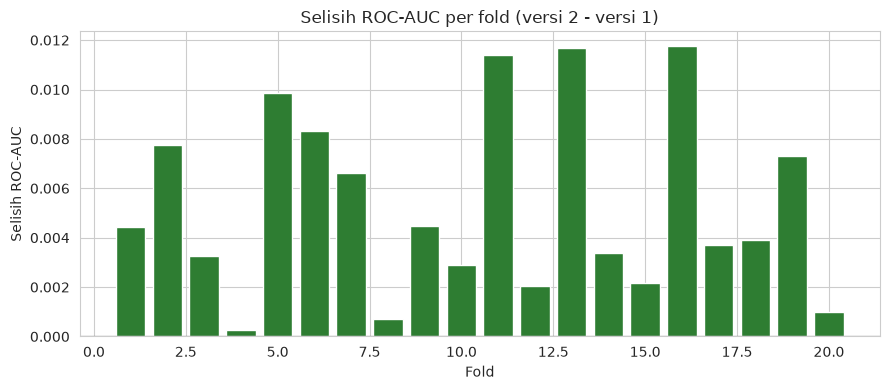

,Versi 1 (RFM),"Versi 2 (+CustomerAge, RecencyRatio)",Selisih (v2 - v1)
Rata-rata ROC-AUC (20 fold),0.7946,0.8,0.0053
Std,0.0182,0.0169,0.0036
Konsistensi,,,20 / 20 fold v2 lebih baik


In [5]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE)
hgb_fixed = lambda: make_pipeline(FunctionTransformer(np.log1p),
                                  HistGradientBoostingClassifier(max_depth=2, learning_rate=0.03, max_iter=300, random_state=RANDOM_STATE))
auc_v1 = cross_val_score(hgb_fixed(), train[FEATURES_CHURN_V1], y_tr, cv=rcv, scoring="roc_auc")
auc_v2 = cross_val_score(hgb_fixed(), train[FEATURES_CHURN], y_tr, cv=rcv, scoring="roc_auc")
diff = auc_v2 - auc_v1

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, 21), diff, color=np.where(diff > 0, "#2e7d32", "#c0392b"))
ax.axhline(0, color="k", lw=0.8)
ax.set(title="Selisih ROC-AUC per fold (versi 2 - versi 1)", xlabel="Fold", ylabel="Selisih ROC-AUC")
plt.tight_layout(); plt.show()

pd.DataFrame({"Versi 1 (RFM)": [round(auc_v1.mean(), 4), round(auc_v1.std(), 4), ""],
              "Versi 2 (+CustomerAge, RecencyRatio)": [round(auc_v2.mean(), 4), round(auc_v2.std(), 4), ""],
              "Selisih (v2 - v1)": [round(diff.mean(), 4), round(diff.std(), 4), f"{(diff > 0).sum()} / {len(diff)} fold v2 lebih baik"]},
             index=["Rata-rata ROC-AUC (20 fold)", "Std", "Konsistensi"])

Versi 2 lebih baik di (hampir) semua fold. Kenaikannya kecil tetapi **konsisten**, artinya bukan kebetulan. Selanjutnya pemilihan algoritma dilakukan dengan fitur versi 2.

### 2.3 Perbandingan algoritma (5-fold cross-validation + tuning)
- **Baseline** `DummyClassifier`: selalu menebak proporsi kelas. Model yang layak harus jauh di atasnya.
- **Logistic Regression**: linear, mudah dijelaskan (perlu `log1p` + scaling).
- **Random Forest** dan **HistGradientBoosting**: berbasis tree, menangkap pola non-linear.

Metrik utama adalah **ROC-AUC** karena tidak bergantung pada threshold dan tidak tertipu kelas mayoritas (baseline yang selalu menebak "churn" sudah mendapat F1 ≈ 0,72).

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
log1p = FunctionTransformer(np.log1p)

candidates = {
    "LogisticRegression": (make_pipeline(log1p, StandardScaler(), LogisticRegression(max_iter=3000)),
                           {"logisticregression__C": [0.1, 1, 10]}),
    "RandomForest": (make_pipeline(log1p, RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
                     {"randomforestclassifier__min_samples_leaf": [5, 20],
                      "randomforestclassifier__max_depth": [6, None]}),
    "HistGradientBoosting": (make_pipeline(log1p, HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
                             {"histgradientboostingclassifier__max_depth": [2, 3],
                              "histgradientboostingclassifier__learning_rate": [0.03, 0.1],
                              "histgradientboostingclassifier__max_iter": [100, 300]}),
}

baseline = cross_validate(DummyClassifier(strategy="prior"), X_tr, y_tr, cv=cv, scoring=["roc_auc", "f1"])
rows = [{"Model": "Baseline (Dummy)", "CV ROC-AUC": baseline["test_roc_auc"].mean(),
         "CV F1": baseline["test_f1"].mean(), "Parameter terbaik": "-"}]
searches = {}
for name, (pipe, grid) in candidates.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring={"roc_auc": "roc_auc", "f1": "f1"},
                      refit="roc_auc", n_jobs=-1).fit(X_tr, y_tr)
    searches[name] = gs
    rows.append({"Model": name, "CV ROC-AUC": gs.best_score_,
                 "CV F1": gs.cv_results_["mean_test_f1"][gs.best_index_],
                 "Parameter terbaik": {k.split("__")[1]: v for k, v in gs.best_params_.items()}})
cv_table = pd.DataFrame(rows).set_index("Model")
cv_table.round(4)

,CV ROC-AUC,CV F1,Parameter terbaik
Model,,,
Baseline (Dummy),0.5000,0.7227,-
LogisticRegression,0.7881,0.7682,{'C': 1}
RandomForest,0.8002,0.7708,"{'max_depth': 6, 'min_samples_leaf': 5}"
HistGradientBoosting,0.7991,0.7744,"{'learning_rate': 0.03, 'max_depth': 2, 'max_i..."


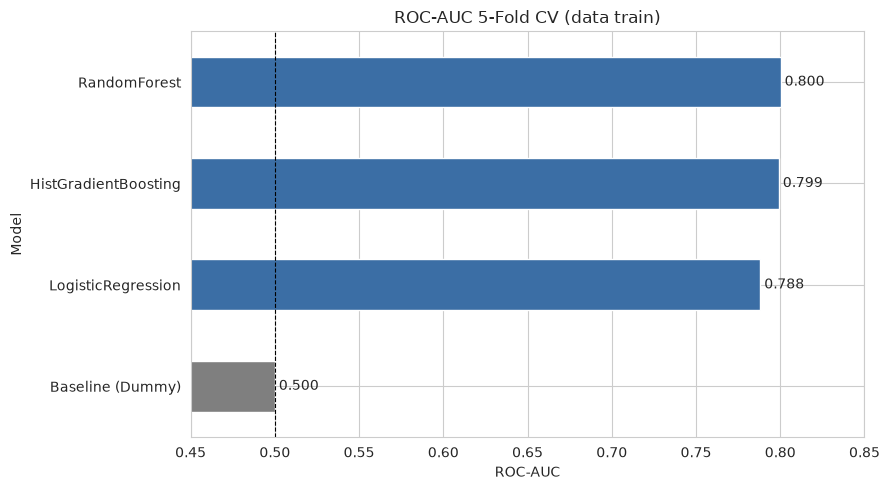

Model terpilih: RandomForest {'randomforestclassifier__max_depth': 6, 'randomforestclassifier__min_samples_leaf': 5}


In [7]:
best_name = max(searches, key=lambda n: searches[n].best_score_)
best_cls = searches[best_name].best_estimator_

ax = cv_table["CV ROC-AUC"].sort_values().plot.barh(color=["#7f7f7f" if "Dummy" in i else "#3b6ea5"
                                                         for i in cv_table["CV ROC-AUC"].sort_values().index])
ax.axvline(0.5, color="k", lw=0.8, ls="--")
ax.set(title="ROC-AUC 5-Fold CV (data train)", xlabel="ROC-AUC", xlim=(0.45, 0.85))
for i, v in enumerate(cv_table["CV ROC-AUC"].sort_values()):
    ax.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()
print("Model terpilih:", best_name, searches[best_name].best_params_)

### 2.4 Menentukan threshold
Threshold default 0,5 belum tentu terbaik. Threshold dipilih dengan **Youden's J** (maksimum TPR − FPR) dari prediksi *out-of-fold* pada data **train**, sehingga data test tetap tidak tersentuh.

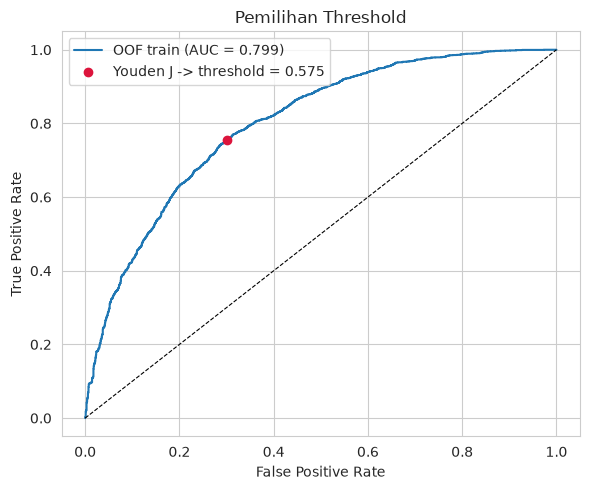

In [8]:
oof = cross_val_predict(best_cls, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
fpr, tpr, thr = roc_curve(y_tr, oof)
j = np.argmax(tpr - fpr)
THRESHOLD = float(thr[j])

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"OOF train (AUC = {roc_auc_score(y_tr, oof):.3f})")
plt.scatter(fpr[j], tpr[j], color="crimson", zorder=3, label=f"Youden J -> threshold = {THRESHOLD:.3f}")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("Pemilihan Threshold")
plt.legend(); plt.tight_layout(); plt.show()

### 2.5 Evaluasi pada data test

In [9]:
p_te = best_cls.predict_proba(X_te)[:, 1]
yhat = (p_te >= THRESHOLD).astype(int)
test_metrics = {
    "test_roc_auc": roc_auc_score(y_te, p_te),
    "test_accuracy": (yhat == y_te).mean(),
    "test_precision": precision_score(y_te, yhat),
    "test_recall": recall_score(y_te, yhat),
    "test_f1": f1_score(y_te, yhat),
}
print(classification_report(y_te, yhat, target_names=["Tidak Churn", "Churn"], digits=3))
pd.Series(test_metrics, name=best_name).round(4).to_frame()

              precision    recall  f1-score   support

 Tidak Churn      0.696     0.716     0.706       571
       Churn      0.777     0.759     0.768       744

    accuracy                          0.741      1315
   macro avg      0.736     0.738     0.737      1315
weighted avg      0.742     0.741     0.741      1315



,RandomForest
test_roc_auc,0.8106
test_accuracy,0.7407
test_precision,0.7772
test_recall,0.7594
test_f1,0.7682


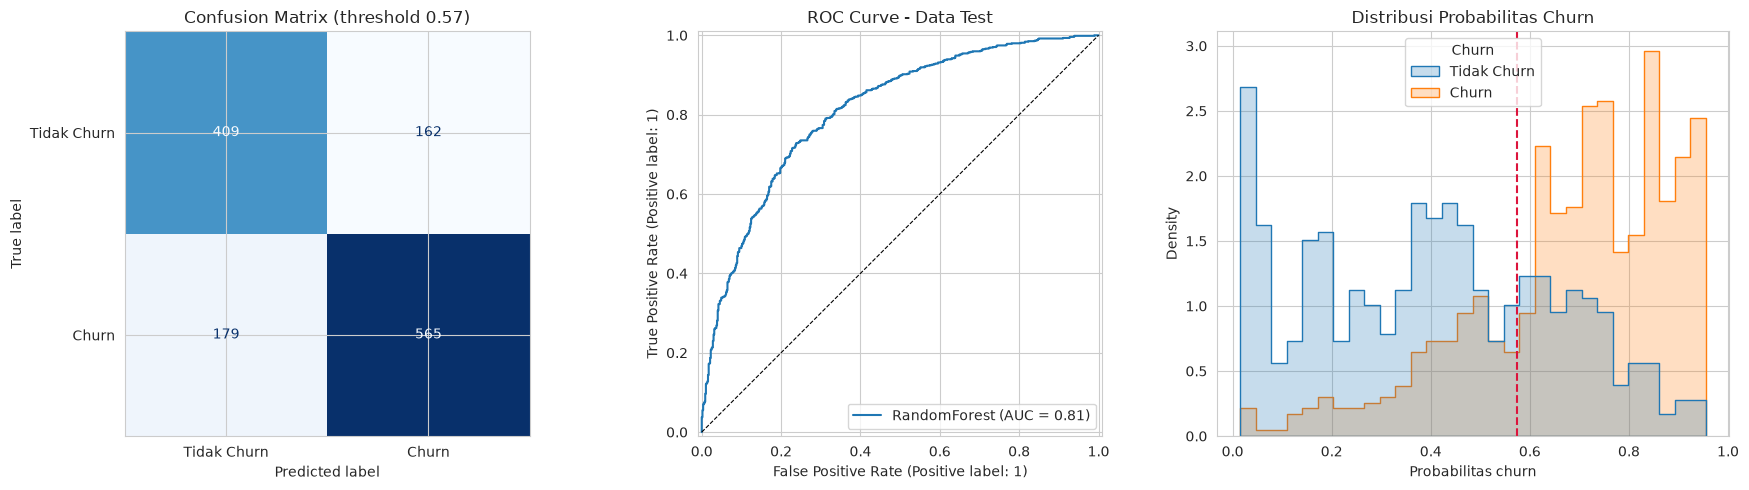

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_te, yhat, display_labels=["Tidak Churn", "Churn"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion Matrix (threshold {THRESHOLD:.2f})")
RocCurveDisplay.from_predictions(y_te, p_te, ax=axes[1], name=best_name)
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8); axes[1].set_title("ROC Curve - Data Test")
sns.histplot(x=p_te, hue=y_te.map({0: "Tidak Churn", 1: "Churn"}), bins=30, stat="density",
             common_norm=False, element="step", ax=axes[2])
axes[2].axvline(THRESHOLD, color="crimson", ls="--", label="threshold")
axes[2].set(title="Distribusi Probabilitas Churn", xlabel="Probabilitas churn")
plt.tight_layout(); plt.show()

**Level risiko untuk website.** Probabilitas dikelompokkan menjadi `RENDAH` (< 0,4), `SEDANG` (0,4-0,7), `TINGGI` (≥ 0,7). Tabel berikut memvalidasi bahwa makin tinggi level risiko, makin tinggi pula churn yang benar-benar terjadi di data test.

In [11]:
def risk_level(p):
    return next(name for lo, hi, name in RISK_BANDS if lo <= p < hi)

band = pd.DataFrame({"Level": [risk_level(p) for p in p_te], "Churn aktual": y_te.values})
band.groupby("Level")["Churn aktual"].agg(Jumlah="size", Churn_aktual="mean").reindex(["RENDAH", "SEDANG", "TINGGI"]).round(3)

,Jumlah,Churn_aktual
Level,,
RENDAH,354,0.206
SEDANG,471,0.554
TINGGI,490,0.837


### 2.6 Interpretasi: fitur mana yang paling berpengaruh?

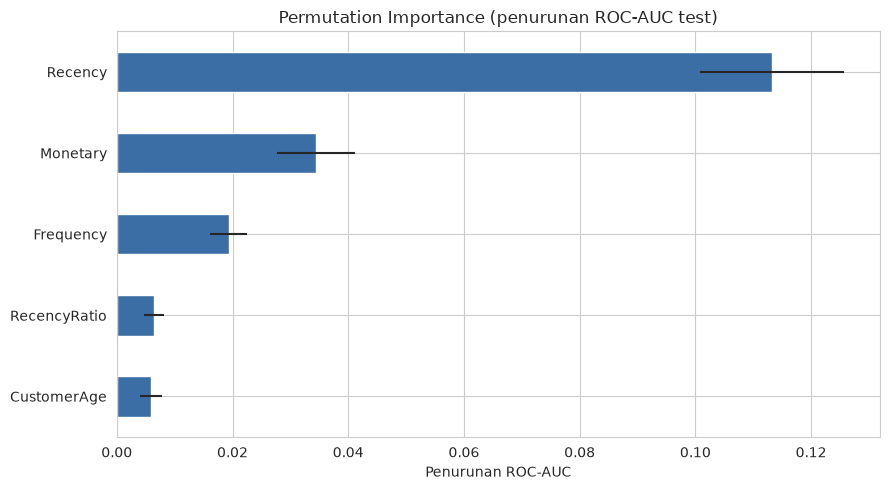

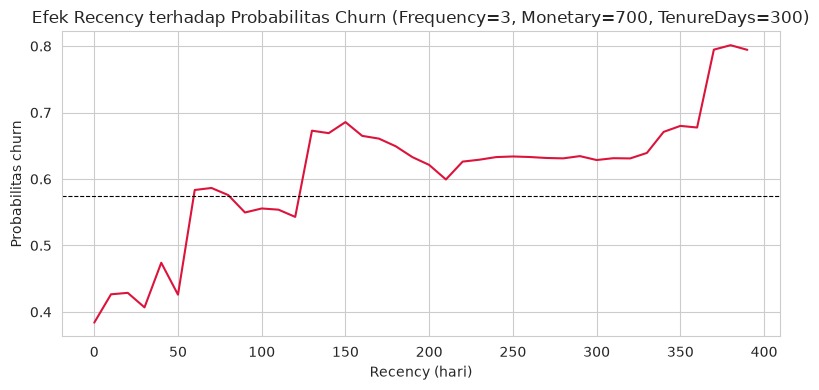

In [12]:
pi = permutation_importance(best_cls, X_te, y_te, n_repeats=20, random_state=RANDOM_STATE, scoring="roc_auc")
imp = pd.Series(pi.importances_mean, index=FEATURES_CHURN).sort_values()
ax = imp.plot.barh(color="#3b6ea5", xerr=pi.importances_std[np.argsort(pi.importances_mean)])
ax.set(title="Permutation Importance (penurunan ROC-AUC test)", xlabel="Penurunan ROC-AUC")
plt.tight_layout(); plt.show()

grid = add_derived(pd.DataFrame({"Recency": np.arange(0, 400, 10), "Frequency": 3, "Monetary": 700, "TenureDays": 300}))[FEATURES_CHURN]
plt.figure(figsize=(8, 4))
plt.plot(grid["Recency"], best_cls.predict_proba(grid)[:, 1], color="crimson")
plt.axhline(THRESHOLD, ls="--", color="k", lw=0.8)
plt.title("Efek Recency terhadap Probabilitas Churn (Frequency=3, Monetary=700, TenureDays=300)")
plt.xlabel("Recency (hari)"); plt.ylabel("Probabilitas churn"); plt.tight_layout(); plt.show()

### 2.7 Refit model final
Setelah evaluasi selesai, model dengan parameter terbaik dilatih ulang pada **seluruh** data (train + test) agar memakai informasi maksimal. Metrik yang dilaporkan tetap metrik test di atas.

In [13]:
churn_model = sklearn.clone(best_cls).fit(cls[FEATURES_CHURN], cls["Churn"])
churn_meta = {
    "algorithm": best_name, "params": {k: str(v) for k, v in searches[best_name].best_params_.items()},
    "features": FEATURES_CHURN, "threshold": round(THRESHOLD, 4), "risk_bands": RISK_BANDS,
    "horizon_days": CHURN_DAYS, "n_customers": int(len(cls)), "churn_rate": round(float(cls["Churn"].mean()), 4),
    "metrics": {"cv_roc_auc": cv_table["CV ROC-AUC"].round(4).to_dict(),
                **{k: round(float(v), 4) for k, v in test_metrics.items()}},
}
churn_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('functiontransformer', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Recency','Frequency','Monetary','CustomerAge','RecencyRatio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<ufunc 'log1p'>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


## 3. Model 2 - Clustering: Segmentasi Pelanggan
### 3.1 Menentukan jumlah cluster (k)
Pipeline: `log1p` → `StandardScaler` → `KMeans` dengan **6 fitur** (versi 2: + `CustomerAge`). Dicoba k = 2..8 dengan metode **elbow** (inertia), **silhouette** (naik = baik), dan **Davies-Bouldin** (turun = baik).

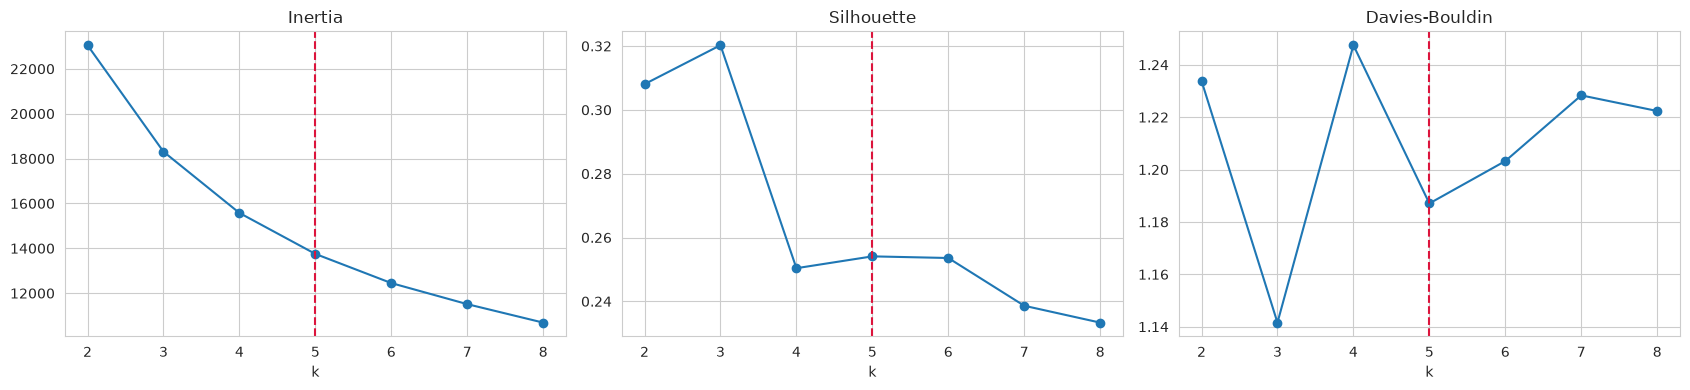

,Inertia,Silhouette,Davies-Bouldin,Cluster terkecil (%)
k,,,,
2,23051.590,0.308,1.234,42.208
3,18307.374,0.320,1.142,14.491
4,15576.318,0.250,1.247,13.397
5,13750.667,0.254,1.187,12.526
6,12450.773,0.254,1.203,7.553
7,11511.676,0.239,1.228,5.451
8,10688.663,0.233,1.222,5.144


In [14]:
X_clu = clu[FEATURES_SEGMENT].astype(float)
def segment_pipeline(k, seed=RANDOM_STATE):
    return make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                         KMeans(n_clusters=k, n_init=10, random_state=seed))

rows = []
for k in range(2, 9):
    m = segment_pipeline(k).fit(X_clu)
    Z, lab = m[:-1].transform(X_clu), m[-1].labels_
    rows.append({"k": k, "Inertia": m[-1].inertia_, "Silhouette": silhouette_score(Z, lab),
                 "Davies-Bouldin": davies_bouldin_score(Z, lab), "Cluster terkecil (%)": np.bincount(lab).min() / len(lab) * 100})
k_table = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["Inertia", "Silhouette", "Davies-Bouldin"]):
    ax.plot(k_table.index, k_table[col], marker="o")
    ax.axvline(N_CLUSTERS, color="crimson", ls="--")
    ax.set(title=col, xlabel="k")
plt.tight_layout(); plt.show()
k_table.round(3)

Secara angka, **k = 3** punya silhouette dan Davies-Bouldin terbaik. Namun angka itu tinggi karena k = 3 hanya membuat kelompok kasar:
- "aktif" (± 38 %) menggabungkan pelanggan VIP dengan pelanggan biasa,
- "tidak aktif" (± 47 %) menggabungkan pelanggan yang **mulai** pergi dengan yang **sudah lama** pergi,
- "baru" (± 15 %).

Kelompok kasar seperti ini tidak bisa diberi aksi berbeda (program VIP ≠ cross-sell; win-back ≠ re-aktivasi massal). **k = 4** masih menggabungkan "mulai hilang" dengan "hilang".

**k = 5** dipilih karena:
1. Inilah k terkecil yang mempertahankan **keempat segmen bisnis** (LOYAL, POTENSIAL, BERISIKO, HILANG) **dan** memisahkan pelanggan **BARU**. Segmen BARU dibentuk K-Means sendiri dari data, bukan aturan manual.
2. Kualitasnya tetap setara versi 1 (silhouette ± 0,25) dengan Davies-Bouldin lebih baik daripada k = 4.
3. Cluster terkecil masih > 10 %, sedangkan k ≥ 6 menghasilkan cluster < 8 %.

Ini kompromi yang wajar dalam segmentasi pelanggan: metrik internal dipakai untuk menyaring, lalu **kegunaan bisnis** menentukan pilihan akhir.

### 3.2 Melatih model & memberi nama segmen otomatis
Nomor cluster K-Means acak (bisa berubah setiap retrain). Agar nama segmen di website konsisten:
1. Cluster dengan pusat `CustomerAge` **terkecil** diberi nama **BARU**.
2. Sisanya diberi skor nilai pelanggan `−Recency + Frequency + Monetary + UniqueProducts` (ruang ter-scale), lalu diurutkan dan dipetakan ke `SEGMENT_CATALOG` (LOYAL → POTENSIAL → BERISIKO → HILANG).

In [15]:
segment_model = segment_pipeline(N_CLUSTERS).fit(X_clu)
labels = segment_model[-1].labels_
Z = segment_model[:-1].transform(X_clu)

def name_clusters(model, features=FEATURES_SEGMENT):
    cen = pd.DataFrame(model[-1].cluster_centers_, columns=features)
    names, rest = {}, list(cen.index)
    if "CustomerAge" in features and len(cen) > len(SEGMENT_CATALOG):
        new_c = cen["CustomerAge"].idxmin()                       # umur pelanggan termuda -> BARU
        names[str(int(new_c))] = {**NEW_SEGMENT, "rank": len(cen)}
        rest.remove(new_c)
    score = -cen.loc[rest, "Recency"] + cen.loc[rest, "Frequency"] + cen.loc[rest, "Monetary"] + cen.loc[rest, "UniqueProducts"]
    for rank, cid in enumerate(score.sort_values(ascending=False).index):
        names[str(int(cid))] = {**SEGMENT_CATALOG[rank], "rank": rank + 1}
    return names

clusters = name_clusters(segment_model)
clu["Segment"] = [clusters[str(c)]["code"] for c in labels]

profile = clu.groupby("Segment")[PROFILE_COLS].median()
profile["Jumlah"] = clu["Segment"].value_counts()
profile["%"] = (profile["Jumlah"] / len(clu) * 100).round(1)
SEG_ORDER = [c["code"] for c in SEGMENT_CATALOG] + [NEW_SEGMENT["code"]]
profile = profile.loc[[c for c in SEG_ORDER if c in profile.index]]
for cid, info in clusters.items():
    info["median_profile"] = profile.loc[info["code"], PROFILE_COLS].round(2).to_dict()
    info["size"] = int(profile.loc[info["code"], "Jumlah"])
profile.round(2)

,Recency,Frequency,Monetary,AvgBasketValue,UniqueProducts,CustomerAge,TenureDays,ReturnRate,Jumlah,%
Segment,,,,,,,,,,
LOYAL,17.0,13.0,4472.46,17.06,178.0,676.0,631.0,0.14,1219,20.8
POTENSIAL,101.0,4.0,1256.82,18.60,50.0,578.0,370.0,0.11,1621,27.7
BERISIKO,306.0,2.0,472.86,6.21,61.0,523.0,161.0,0.00,891,15.2
HILANG,411.0,1.0,248.40,18.08,12.0,469.5,0.0,0.00,1388,23.7
BARU,29.0,1.0,379.99,16.22,25.0,61.0,0.0,0.00,733,12.5


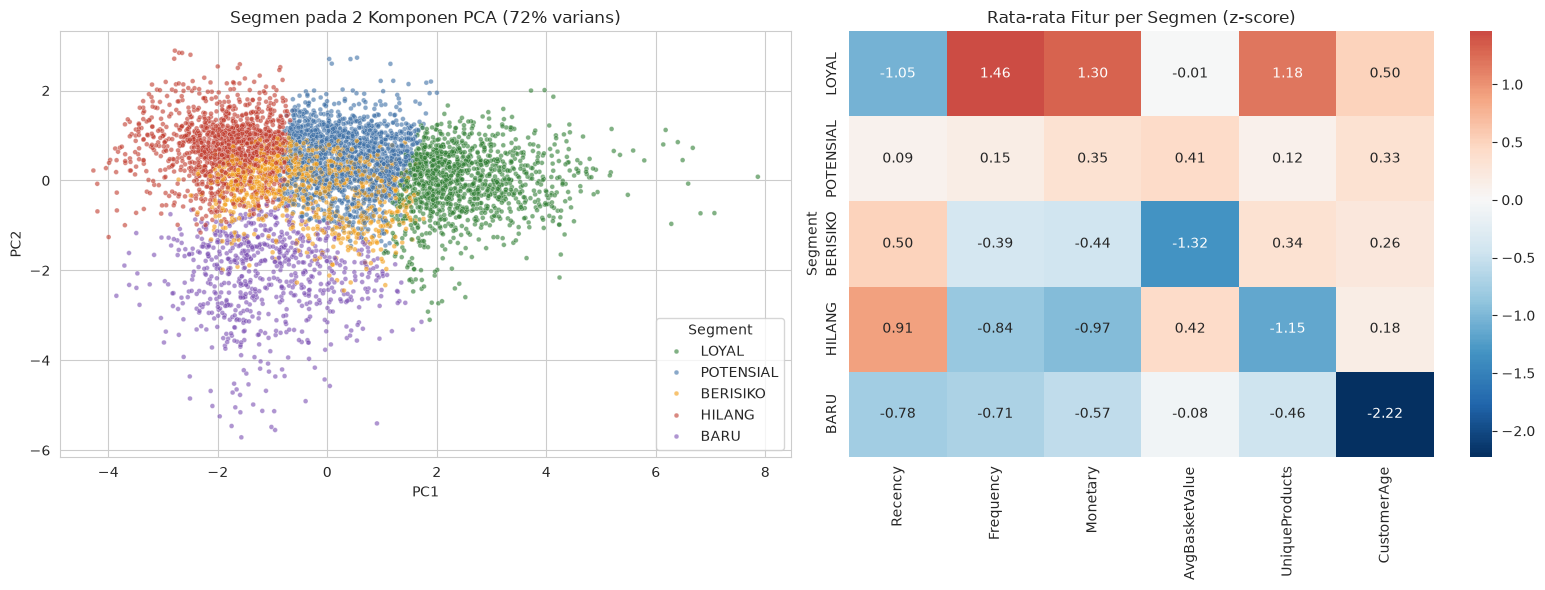

In [16]:
order = [c for c in SEG_ORDER if c in set(clu["Segment"])]
pal = {"LOYAL": "#2e7d32", "POTENSIAL": "#3b6ea5", "BERISIKO": "#f39c12", "HILANG": "#c0392b", "BARU": "#7b4fb3"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
pc = PCA(2, random_state=RANDOM_STATE).fit(Z)
P = pc.transform(Z)
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=clu["Segment"], hue_order=order, palette=pal, s=12, alpha=0.6, ax=axes[0])
axes[0].set(title=f"Segmen pada 2 Komponen PCA ({pc.explained_variance_ratio_.sum():.0%} varians)", xlabel="PC1", ylabel="PC2")

prof_z = pd.DataFrame(Z, columns=FEATURES_SEGMENT).assign(Segment=clu["Segment"]).groupby("Segment").mean().loc[order]
sns.heatmap(prof_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("Rata-rata Fitur per Segmen (z-score)")
plt.tight_layout(); plt.show()

**Interpretasi segmen:**
- **LOYAL**: baru saja belanja, sering, nilai belanja dan ragam produk tertinggi → pertahankan dengan program loyalitas.
- **POTENSIAL**: masih aktif dengan frekuensi menengah → dorong naik kelas dengan cross-sell (memakai Model 3).
- **BERISIKO**: sudah lama tidak belanja (median ± 7 bulan), frekuensi rendah, dan nilai per baris belanja paling kecil (banyak produk murah) → kampanye *win-back*.
- **HILANG**: rata-rata hanya sekali belanja dan sudah lebih dari setahun tidak kembali → re-aktivasi berbiaya rendah.
- **BARU** *(versi 2)*: umur pelanggan masih muda (pembelian pertama baru-baru ini), baru 1–2 kali belanja → onboarding agar terjadi pembelian kedua.

### 3.3 Versi 1 vs Versi 2: apakah pelanggan baru masih "salah segmen"?
"Pelanggan baru" = pembelian pertama & terakhir dalam 30 hari terakhir (`TenureDays ≤ 30` dan `Recency ≤ 30`).

In [17]:
newmask = ((clu["TenureDays"] <= 30) & (clu["Recency"] <= 30)).values

def evaluate_segmentation(features, k):
    m = segment_pipeline(k).fit(clu[features].astype(float))
    Zx, lab = m[:-1].transform(clu[features].astype(float)), m[-1].labels_
    names = name_clusters(m, features)
    seg = np.array([names[str(c)]["code"] for c in lab])
    ari_x = np.mean([adjusted_rand_score(lab, segment_pipeline(k, s).fit(clu[features].astype(float))[-1].labels_) for s in (1, 2, 3)])
    return {"Fitur": len(features), "k": k, "Silhouette": round(silhouette_score(Zx, lab), 3),
            "Davies-Bouldin": round(davies_bouldin_score(Zx, lab), 3), "Stabilitas ARI": round(ari_x, 3),
            "Cluster terkecil (%)": round(np.bincount(lab).min() / len(lab) * 100, 1),
            f"Pelanggan baru (n={newmask.sum()}) masuk HILANG": int((seg[newmask] == "HILANG").sum()),
            "... masuk BERISIKO": int((seg[newmask] == "BERISIKO").sum()),
            "... masuk BARU": int((seg[newmask] == "BARU").sum())}

compare_seg = pd.DataFrame([evaluate_segmentation(FEATURES_SEGMENT_V1, N_CLUSTERS_V1),
                            evaluate_segmentation(FEATURES_SEGMENT, N_CLUSTERS)],
                           index=["Versi 1 (5 fitur, k=4)", "Versi 2 (+CustomerAge, k=5)"]).T
compare_seg

,"Versi 1 (5 fitur, k=4)","Versi 2 (+CustomerAge, k=5)"
Fitur,5.000,6.000
k,4.000,5.000
Silhouette,0.255,0.254
Davies-Bouldin,1.256,1.187
Stabilitas ARI,0.988,0.999
Cluster terkecil (%),17.500,12.500
Pelanggan baru (n=190) masuk HILANG,84.000,0.000
... masuk BERISIKO,52.000,0.000
... masuk BARU,0.000,190.000


Di versi 1, sebagian besar pelanggan baru dianggap **HILANG/BERISIKO** karena Frequency, Monetary, dan ragam produknya sama kecilnya dengan pelanggan lama yang sudah pergi. Di versi 2, `CustomerAge` membedakan keduanya, sehingga pelanggan baru berkumpul di segmen **BARU**. Kualitas cluster (silhouette, Davies-Bouldin) tetap setara atau lebih baik, dan stabilitasnya naik.

### 3.4 Uji stabilitas
Model dilatih ulang dengan 5 *random seed* berbeda. Bila **Adjusted Rand Index (ARI)** terhadap model utama mendekati 1, segmen stabil dan tidak bergantung pada kebetulan inisialisasi.

In [18]:
ari = [adjusted_rand_score(labels, segment_pipeline(N_CLUSTERS, seed).fit(X_clu)[-1].labels_) for seed in range(1, 6)]
print("ARI per seed:", np.round(ari, 3), "| rata-rata:", round(float(np.mean(ari)), 3))

segment_meta = {
    "algorithm": "KMeans", "k": N_CLUSTERS, "features": FEATURES_SEGMENT,
    "preprocessing": "log1p + StandardScaler", "clusters": clusters,
    "metrics": {"silhouette": round(float(silhouette_score(Z, labels)), 4),
                "davies_bouldin": round(float(davies_bouldin_score(Z, labels)), 4),
                "min_cluster_share": round(float(np.bincount(labels).min() / len(labels)), 4),
                "stability_ari": round(float(np.mean(ari)), 4)},
    "n_customers": int(len(clu)),
}
pd.Series(segment_meta["metrics"]).to_frame("Nilai")

ARI per seed: [0.997 1.    0.999 0.992 0.999] | rata-rata: 0.997


,Nilai
silhouette,0.2541
davies_bouldin,1.1871
min_cluster_share,0.1253
stability_ari,0.9974


## 4. Model 3 - Association Rules: Rekomendasi Produk
### 4.1 FP-Growth
FP-Growth dipilih dibanding Apriori karena jauh lebih cepat pada matriks lebar (2.765 produk) dan hasilnya identik. Parameter:
- `min_support = 0.005` *(versi 2, sebelumnya 0,01)*: itemset muncul di ≥ 0,5 % invoice (± 180 invoice). Pola masih cukup umum, dan cakupan produk naik ± 3×. Pemilihannya dibuktikan di Bagian 4.2.
- `min_confidence = 0.3` dan `lift ≥ 2`: rule cukup sering benar dan minimal 2× lebih mungkin dibanding kebetulan.
- `max_len = 3`: rule maksimal 3 produk agar mudah ditampilkan di web.

In [19]:
def mine_rules(b, min_support=RULES_MIN_SUPPORT):
    fi = fpgrowth(b, min_support=min_support, use_colnames=True, max_len=RULES_MAX_LEN)
    r = association_rules(fi, metric="confidence", min_threshold=RULES_MIN_CONFIDENCE)
    r = r[r["lift"] >= RULES_MIN_LIFT].sort_values("lift", ascending=False).reset_index(drop=True)
    return fi, r

itemsets, rules_df = mine_rules(basket)
print(f"Frequent itemsets: {len(itemsets):,} | Rules (conf >= {RULES_MIN_CONFIDENCE}, lift >= {RULES_MIN_LIFT}): {len(rules_df):,}")
show = rules_df.head(10).copy()
show["antecedents"] = show["antecedents"].map(lambda s: ", ".join(sorted(s)))
show["consequents"] = show["consequents"].map(lambda s: ", ".join(sorted(s)))
show[["antecedents", "consequents", "support", "confidence", "lift"]].round(3)

Frequent itemsets: 2,527 | Rules (conf >= 0.3, lift >= 2.0): 1,731


,antecedents,consequents,support,confidence,lift
0,HERB MARKER ROSEMARY,HERB MARKER THYME,0.005,0.924,173.738
1,HERB MARKER THYME,HERB MARKER ROSEMARY,0.005,0.948,173.738
2,"REGENCY TEA PLATE GREEN, REGENCY TEA PLATE ROSES",REGENCY TEA PLATE PINK,0.005,0.808,130.845
3,REGENCY TEA PLATE PINK,"REGENCY TEA PLATE GREEN, REGENCY TEA PLATE ROSES",0.005,0.826,130.845
4,"REGENCY TEA PLATE PINK, REGENCY TEA PLATE ROSES",REGENCY TEA PLATE GREEN,0.005,0.939,126.185
5,REGENCY TEA PLATE GREEN,"REGENCY TEA PLATE PINK, REGENCY TEA PLATE ROSES",0.005,0.685,126.185
6,CHILDRENS GARDEN GLOVES PINK,CHILDRENS GARDEN GLOVES BLUE,0.005,0.775,121.194
7,CHILDRENS GARDEN GLOVES BLUE,CHILDRENS GARDEN GLOVES PINK,0.005,0.802,121.194
8,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN,0.006,0.902,121.173
9,REGENCY TEA PLATE GREEN,REGENCY TEA PLATE PINK,0.006,0.748,121.173


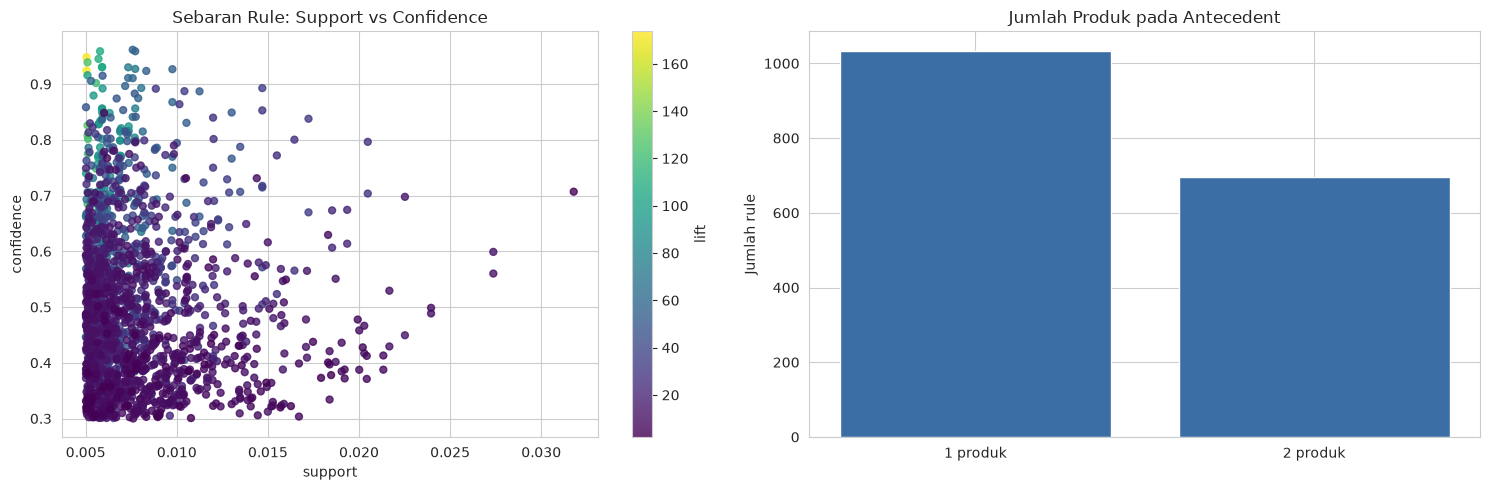

Produk yang bisa memicu rekomendasi: 401


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sc = axes[0].scatter(rules_df["support"], rules_df["confidence"], c=rules_df["lift"], cmap="viridis", s=25, alpha=0.8)
plt.colorbar(sc, ax=axes[0], label="lift")
axes[0].set(title="Sebaran Rule: Support vs Confidence", xlabel="support", ylabel="confidence")

ant_len = rules_df["antecedents"].map(len).value_counts().sort_index()
axes[1].bar([f"{k} produk" for k in ant_len.index], ant_len.values, color="#3b6ea5")
axes[1].set(title="Jumlah Produk pada Antecedent", ylabel="Jumlah rule")
plt.tight_layout(); plt.show()
print(f"Produk yang bisa memicu rekomendasi: {len(set().union(*rules_df['antecedents'])):,}")

### 4.2 Evaluasi temporal (Hit Rate @5) & pemilihan `min_support`
Rule dibentuk dari data **sebelum** 90 hari terakhir, lalu diuji pada invoice di 90 hari terakhir: satu produk dari tiap invoice disembunyikan, dan dicek apakah produk itu muncul di 5 rekomendasi teratas dari produk lain di invoice tersebut. Hasilnya dibandingkan dengan baseline "rekomendasikan produk terpopuler". Uji ini diulang untuk beberapa nilai `min_support`.

In [21]:
def recommend_from_rules(rules, popular, items, top_n=5):
    cart, best = set(items), {}
    for r in rules:
        if set(r["antecedents"]) <= cart:
            for c in r["consequents"]:
                if c not in cart and (c not in best or (r["lift"], r["confidence"]) > best[c][0]):
                    best[c] = ((r["lift"], r["confidence"]), r)
    recs = [{"product": c, "confidence": round(r["confidence"], 4), "lift": round(r["lift"], 2),
             "because_of": r["antecedents"], "source": "association_rule"}
            for c, (s, r) in sorted(best.items(), key=lambda kv: kv[1][0], reverse=True)]
    recs += [{"product": p, "confidence": None, "lift": None, "because_of": [], "source": "popular"}
             for p in popular if p not in cart and p not in best]
    return recs[:top_n]

def rules_to_records(r):
    return [{"antecedents": sorted(a), "consequents": sorted(c), "support": round(float(s), 5),
             "confidence": round(float(cf), 4), "lift": round(float(l), 3)}
            for a, c, s, cf, l in r[["antecedents", "consequents", "support", "confidence", "lift"]].itertuples(index=False)]

def baskets_from(df, min_freq=MIN_ITEM_FREQ_FOR_BASKET):
    src = df[(~df["IsCancelled"]) & (df["Quantity"] > 0)]
    keep = src["Description"].value_counts().loc[lambda s: s >= min_freq].index
    long = src[src["Description"].isin(keep)][["Invoice", "Description"]].drop_duplicates()
    return pd.crosstab(long["Invoice"], long["Description"]).astype(bool)

split_date = trans["InvoiceDate"].max() + pd.Timedelta(days=1) - pd.Timedelta(days=CHURN_DAYS)
old, new = trans[trans["InvoiceDate"] < split_date], trans[trans["InvoiceDate"] >= split_date]
b_old = baskets_from(old)
popular_old = b_old.sum().sort_values(ascending=False).index[:50].tolist()
test_lists = new[(~new["IsCancelled"]) & (new["Quantity"] > 0)].groupby("Invoice")["Description"].agg(lambda s: sorted(set(s)))
test_lists = [x for x in test_lists if len(x) >= 2]

def hit_rate(rules, popular, n=5000, k=5):
    rng = np.random.default_rng(RANDOM_STATE)          # seed sama -> invoice & produk tersembunyi sama untuk semua support
    hits = base = 0
    idx = rng.permutation(len(test_lists))[:n]
    for i in idx:
        items = test_lists[i]
        hidden = items[rng.integers(len(items))]
        rest = [x for x in items if x != hidden]
        hits += hidden in [r["product"] for r in recommend_from_rules(rules, popular, rest, k)]
        base += hidden in [p for p in popular if p not in rest][:k]
    return hits / len(idx), base / len(idx), len(idx)

rows = []
for ms in [0.01, 0.0075, 0.005, 0.003]:
    rr = rules_to_records(mine_rules(b_old, ms)[1])
    hr, base_hr, n_inv = hit_rate(rr, popular_old)
    rows.append({"min_support": ms, "Jumlah rule": len(rr),
                 "Produk pemicu": len(set().union(*[set(x["antecedents"]) for x in rr])) if rr else 0,
                 "Hit@5": round(hr, 4), "Baseline populer": round(base_hr, 4)})
support_table = pd.DataFrame(rows).set_index("min_support")
display(support_table)

sel = support_table.loc[RULES_MIN_SUPPORT]
rules_eval = {"hit_rate_at_k": float(sel["Hit@5"]), "popular_baseline": float(sel["Baseline populer"]),
              "k": 5, "n_test_invoices": int(n_inv), "n_rules_train": int(sel["Jumlah rule"]),
              "support_comparison": support_table.reset_index().to_dict("records")}
pd.Series({k: v for k, v in rules_eval.items() if k != "support_comparison"}).to_frame("Nilai (support terpilih)")

,Jumlah rule,Produk pemicu,Hit@5,Baseline populer
min_support,,,,
0.0100,298,127,0.0838,0.0254
0.0075,693,227,0.1000,0.0254
0.0050,1819,402,0.1182,0.0254
0.0030,5438,737,0.1314,0.0254


,Nilai (support terpilih)
hit_rate_at_k,0.1182
popular_baseline,0.0254
k,5.0000
n_test_invoices,5000.0000
n_rules_train,1819.0000


Makin kecil `min_support`, makin banyak produk yang punya rule, sehingga Hit@5 naik. Namun rule dari pola yang makin jarang juga makin tidak andal, dan jumlah rule membengkak (lebih berat di web). **`min_support = 0,005`** dipilih sebagai titik seimbang:
- Hit@5 naik ± 40 % dari versi 1 dengan produk pemicu ± 3×.
- Setiap itemset masih didukung ± 180 invoice.
- Jumlah rule masih ringan untuk dihitung real-time.

Penurunan lebih jauh (0,3 %) hanya menambah sedikit akurasi, tetapi jumlah rule naik 3× lipat.

In [22]:
rules_records = rules_to_records(rules_df)                     # model final: seluruh data
popular = basket.sum().sort_values(ascending=False).index[:50].tolist()
rules_meta = {"algorithm": "FP-Growth", "min_support": RULES_MIN_SUPPORT, "min_confidence": RULES_MIN_CONFIDENCE,
              "min_lift": RULES_MIN_LIFT, "max_len": RULES_MAX_LEN, "n_invoices": int(basket.shape[0]),
              "n_products": int(basket.shape[1]), "n_rules": len(rules_records), "evaluation": rules_eval}
recommend_from_rules(rules_records, popular, ["POPPY'S PLAYHOUSE BEDROOM"], top_n=5)

[{'product': "POPPY'S PLAYHOUSE BATHROOM",
  'confidence': 0.4784,
  'lift': 59.44,
  'because_of': ["POPPY'S PLAYHOUSE BEDROOM"],
  'source': 'association_rule'},
 {'product': "POPPY'S PLAYHOUSE LIVINGROOM",
  'confidence': 0.4784,
  'lift': 59.44,
  'because_of': ["POPPY'S PLAYHOUSE BEDROOM"],
  'source': 'association_rule'},
 {'product': "POPPY'S PLAYHOUSE KITCHEN",
  'confidence': 0.4946,
  'lift': 59.42,
  'because_of': ["POPPY'S PLAYHOUSE BEDROOM"],
  'source': 'association_rule'},
 {'product': 'WHITE HANGING HEART T-LIGHT HOLDER',
  'confidence': None,
  'lift': None,
  'because_of': [],
  'source': 'popular'},
 {'product': 'REGENCY CAKESTAND 3 TIER',
  'confidence': None,
  'lift': None,
  'because_of': [],
  'source': 'popular'}]

## 5. Menyimpan Model untuk Website
```
models/
├── current.json                  <- versi aktif yang dibaca website / API
└── <versi>/
    ├── churn_model.joblib        Pipeline: log1p -> (scaler) -> classifier
    ├── segment_model.joblib      Pipeline: log1p -> StandardScaler -> KMeans
    ├── association_rules.json    rule + 50 produk populer (fallback)
    └── metadata.json             fitur, threshold, batas capping, segmen, metrik
```
Batas capping `Quantity` & `Price` dari TA IV ikut disimpan, karena transaksi baru dari website harus dibersihkan dengan batas yang **sama** dengan data training.

In [23]:
def cap_bounds(df, factor=3):
    out = {}
    for col in ["Quantity", "Price"]:
        q1, q3 = df[col].quantile([0.25, 0.75])
        out[col] = float(q3 + factor * (q3 - q1))
    return out

VERSION = datetime.now().strftime("%Y%m%d-%H%M%S")
metadata = {
    "version": VERSION, "created_at": datetime.now().isoformat(timespec="seconds"),
    "library": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__},
    "data": {"n_transactions": int(len(trans)), "period_start": str(trans["InvoiceDate"].min()),
             "period_end": str(trans["InvoiceDate"].max())},
    "cleaning": {"cap_upper": cap_bounds(trans), "iqr_factor": 3},
    "churn": churn_meta, "segment": segment_meta, "rules": rules_meta,
}

vdir = MODELS_DIR / VERSION
vdir.mkdir(parents=True, exist_ok=True)
joblib.dump(churn_model, vdir / "churn_model.joblib")
joblib.dump(segment_model, vdir / "segment_model.joblib")
(vdir / "association_rules.json").write_text(json.dumps({"rules": rules_records, "popular": popular}, ensure_ascii=False, indent=1))
(vdir / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2, default=str))
(MODELS_DIR / "current.json").write_text(json.dumps({"version": VERSION}, indent=2))

print("Batas capping:", metadata["cleaning"]["cap_upper"])
for f in sorted(vdir.iterdir()):
    print(f"  {f.name:28s} {f.stat().st_size / 1024:8.1f} KB")

Batas capping: {'Quantity': 42.0, 'Price': 11.25}
  association_rules.json          355.7 KB
  churn_model.joblib             2653.7 KB
  metadata.json                     5.2 KB
  segment_model.joblib             25.2 KB


## 6. Simulasi Pemakaian di Website
Bagian ini meniru apa yang dilakukan backend website: **memuat model dari file** (bukan memakai variabel di notebook), lalu memproses input baru.

In [24]:
current = json.loads((MODELS_DIR / "current.json").read_text())["version"]
d = MODELS_DIR / current
M = {"churn": joblib.load(d / "churn_model.joblib"), "segment": joblib.load(d / "segment_model.joblib"),
     "rules": json.loads((d / "association_rules.json").read_text()),
     "meta": json.loads((d / "metadata.json").read_text())}

def predict_customer(feat):
    # feat: dict fitur asli satu pelanggan (termasuk CustomerAge & RecencyRatio) -> hasil siap simpan ke database
    X = pd.DataFrame([feat])
    p = float(M["churn"].predict_proba(X[M["meta"]["churn"]["features"]])[0, 1])
    seg = M["meta"]["segment"]["clusters"][str(int(M["segment"].predict(X[M["meta"]["segment"]["features"]])[0]))]
    return {"churn_probability": round(p, 4), "churn_label": int(p >= M["meta"]["churn"]["threshold"]),
            "risk_level": risk_level(p), "segment_code": seg["code"], "segment_name": seg["name"],
            "action": seg["action"]}

print("Model aktif:", current)
examples = add_derived(pd.DataFrame([
    {"Kasus": "Pelanggan setia", "Recency": 5, "Frequency": 25, "Monetary": 9000, "AvgBasketValue": 22, "UniqueProducts": 180, "TenureDays": 600},
    {"Kasus": "Lama tidak belanja", "Recency": 300, "Frequency": 1, "Monetary": 150, "AvgBasketValue": 15, "UniqueProducts": 10, "TenureDays": 0},
    {"Kasus": "Pelanggan baru (sekali belanja 2 hari lalu)", "Recency": 2, "Frequency": 1, "Monetary": 187, "AvgBasketValue": 15.6, "UniqueProducts": 12, "TenureDays": 0},
]))
pd.DataFrame([{"Kasus": e["Kasus"], **predict_customer(e)} for e in examples.to_dict("records")]).set_index("Kasus")

Model aktif: 20261110-171933


,churn_probability,churn_label,risk_level,segment_code,segment_name,action
Kasus,,,,,,
Pelanggan setia,0.0381,0,RENDAH,LOYAL,Pelanggan Loyal Bernilai Tinggi,"Program loyalitas/VIP, akses awal produk baru"
Lama tidak belanja,0.8515,1,TINGGI,HILANG,Pelanggan Hilang (Sekali Beli),Re-aktivasi biaya rendah (email massal)
Pelanggan baru (sekali belanja 2 hari lalu),0.3894,0,RENDAH,BARU,Pelanggan Baru,"Onboarding: sambutan, rekomendasi produk awal,..."


### 6.1 Input baru: pelanggan melakukan transaksi baru
Fitur pelanggan dihitung ulang dari seluruh riwayatnya ditambah invoice baru, lalu diprediksi lagi. Inilah yang dijalankan website setiap kali ada invoice baru (lihat `CLAUDE.md`).

In [25]:
def build_features(df, ref_date):
    # sama dengan notebook 01 & ml_service: fitur per pelanggan dari transaksi sebelum ref_date
    hist = df[df["InvoiceDate"] < ref_date]
    buy = hist[~hist["IsCancelled"]]
    f = buy.groupby("Customer ID").agg(
        Recency=("InvoiceDate", lambda x: (ref_date - x.max()).days), Frequency=("Invoice", "nunique"),
        Monetary=("TotalPrice", "sum"), AvgBasketValue=("TotalPrice", "mean"),
        UniqueProducts=("StockCode", "nunique"), First=("InvoiceDate", "min"), Last=("InvoiceDate", "max")).reset_index()
    f["TenureDays"] = (f["Last"] - f["First"]).dt.days
    return add_derived(f.drop(columns=["First", "Last"]))

ALL_FEATS = list(dict.fromkeys(FEATURES_CHURN + FEATURES_SEGMENT))

REF = trans["InvoiceDate"].max() + pd.Timedelta(days=1)
feats_now = build_features(trans, REF)
cand = feats_now[(feats_now["Recency"] > 200) & (feats_now["Frequency"] >= 3)].iloc[0]
cid = int(cand["Customer ID"])
before = predict_customer(cand[ALL_FEATS].to_dict())

cap = M["meta"]["cleaning"]["cap_upper"]
new_invoice = pd.DataFrame({
    "Invoice": "WEB000001", "StockCode": ["85123A", "22423", "47566"],
    "Description": ["WHITE HANGING HEART T-LIGHT HOLDER", "REGENCY CAKESTAND 3 TIER", "PARTY BUNTING"],
    "Quantity": [12, 2, 6], "Price": [2.95, 12.75, 4.95], "InvoiceDate": REF - pd.Timedelta(hours=2),
    "Customer ID": cid, "Country": "United Kingdom", "IsCancelled": False})
new_invoice["Quantity"] = new_invoice["Quantity"].clip(upper=cap["Quantity"])   # cleaning dengan batas training
new_invoice["Price"] = new_invoice["Price"].clip(upper=cap["Price"])
new_invoice["TotalPrice"] = new_invoice["Quantity"] * new_invoice["Price"]

hist_cust = pd.concat([trans[trans["Customer ID"] == cid], new_invoice], ignore_index=True)
after_feat = build_features(hist_cust, REF).iloc[0]
after = predict_customer(after_feat[ALL_FEATS].to_dict())

pd.DataFrame({"Sebelum invoice baru": {**cand[ALL_FEATS].to_dict(), **before},
              "Sesudah invoice baru": {**after_feat[ALL_FEATS].to_dict(), **after}})

,Sebelum invoice baru,Sesudah invoice baru
Recency,326.0,0.0
Frequency,3.0,4.0
Monetary,213.04,300.64
CustomerAge,647.0,647.0
RecencyRatio,2.018576,0.0
AvgBasketValue,8.5216,10.737143
UniqueProducts,25.0,28.0
churn_probability,0.6782,0.6134
churn_label,1,1
risk_level,SEDANG,SEDANG


Setelah invoice baru, `Recency` turun drastis dan `Frequency` bertambah, sehingga probabilitas churn langsung turun dan segmen pelanggan ikut berubah. Prediksi selalu dihitung dari data terbaru tanpa perlu melatih ulang model.

### 6.2 Rekomendasi untuk keranjang belanja

In [26]:
cart = ["GREEN REGENCY TEACUP AND SAUCER", "PINK REGENCY TEACUP AND SAUCER"]
print("Isi keranjang:", cart)
pd.DataFrame(recommend_from_rules(M["rules"]["rules"], M["rules"]["popular"], cart, top_n=5))

Isi keranjang: ['GREEN REGENCY TEACUP AND SAUCER', 'PINK REGENCY TEACUP AND SAUCER']


,product,confidence,lift,because_of,source
0,REGENCY CAKESTAND 3 TIER,0.5067,35.49,[PINK REGENCY TEACUP AND SAUCER],association_rule
1,ROSES REGENCY TEACUP AND SAUCER,0.7145,34.89,[PINK REGENCY TEACUP AND SAUCER],association_rule
2,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,[],popular
3,ASSORTED COLOUR BIRD ORNAMENT,NaN,NaN,[],popular
4,JUMBO BAG RED RETROSPOT,NaN,NaN,[],popular


## 7. Strategi Pembaruan Model
Ada dua kegiatan yang berbeda dan sering tertukar:

| Kegiatan | Apa yang berubah | Frekuensi yang disarankan | Alasan |
|---|---|---|---|
| **Scoring** (hitung ulang fitur + prediksi semua pelanggan) | Isi tabel prediksi | **Setiap malam** + langsung saat ada invoice baru | `Recency` bertambah setiap hari walau pelanggan tidak bertransaksi, jadi risiko churn harus diperbarui harian |
| **Retrain Association Rules** | File rules | Mingguan (boleh harian) | Murah (detik), tanpa label, cepat menangkap produk baru |
| **Retrain Churn** | Bobot model | **Bulanan** dengan *quality gate* | Label butuh 90 hari ke depan, sehingga data berlabel baru per hari sangat sedikit. Retrain harian hanya menambah variasi acak tanpa informasi baru |
| **Retrain Clustering** | Pusat cluster | Bulanan / per kuartal | Segmen yang berubah tiap hari membingungkan tim pemasaran. Nama segmen dipetakan ulang otomatis lewat skor centroid |

**Quality gate**: model baru hanya diaktifkan bila ROC-AUC test ≥ 0,70 dan tidak turun lebih dari 0,02 dari model aktif, silhouette ≥ 0,20, cluster terkecil ≥ 5 %, dan rules ≥ 20. Bila gagal, model lama tetap dipakai. Semua versi tersimpan, sehingga rollback cukup dengan mengganti `models/current.json`.

Job ini diimplementasikan di paket `ml_service` (`python -m ml_service.jobs score-all | retrain`).

## 8. Kesimpulan

In [27]:
pd.DataFrame({
    "Model": ["Churn (Classification)", "Segmentasi (Clustering)", "Rekomendasi (Association)"],
    "Algoritma": [best_name, f"K-Means (k={N_CLUSTERS})", "FP-Growth"],
    "Metrik utama": [f"ROC-AUC test {test_metrics['test_roc_auc']:.3f} (baseline 0,500)",
                     f"Silhouette {segment_meta['metrics']['silhouette']:.3f}, ARI stabilitas {segment_meta['metrics']['stability_ari']:.2f}",
                     f"Hit@5 {rules_eval['hit_rate_at_k']:.1%} vs populer {rules_eval['popular_baseline']:.1%}"],
    "Dipakai di web untuk": ["Daftar pelanggan berisiko + level risiko", "Label segmen + aksi pemasaran", "Rekomendasi produk di keranjang"],
    "File": ["churn_model.joblib", "segment_model.joblib", "association_rules.json"],
}).set_index("Model")

,Algoritma,Metrik utama,Dipakai di web untuk,File
Model,,,,
Churn (Classification),RandomForest,"ROC-AUC test 0.811 (baseline 0,500)",Daftar pelanggan berisiko + level risiko,churn_model.joblib
Segmentasi (Clustering),K-Means (k=5),"Silhouette 0.254, ARI stabilitas 1.00",Label segmen + aksi pemasaran,segment_model.joblib
Rekomendasi (Association),FP-Growth,Hit@5 11.8% vs populer 2.5%,Rekomendasi produk di keranjang,association_rules.json


1. **Churn**: model terbaik dipilih otomatis dari 3 kandidat lewat 5-fold CV dan jauh mengungguli baseline. Threshold ditentukan dari data train (Youden's J), dan level risiko tervalidasi: makin tinggi level, makin tinggi churn aktual.
2. **Segmentasi**: 5 segmen (LOYAL, POTENSIAL, BERISIKO, HILANG, **BARU**) stabil terhadap random seed dan mudah diterjemahkan ke aksi pemasaran. Pelanggan baru tidak lagi salah masuk segmen HILANG.
3. **Rekomendasi**: rule FP-Growth lolos uji temporal dan lebih akurat daripada sekadar menawarkan produk terpopuler.
4. **Siap deployment**: preprocessing ada di dalam pipeline, model berversi dengan metadata, dan simulasi menunjukkan input baru dari website langsung menghasilkan prediksi terbaru.